# Figure 5: 50 random PDB complexes before and after the cutoffs

50 random PDB complexes released before the cutoffs (2017-2021) and 50 released after (deposited and released after 2025-06-30, OBv0's cutoff), single seed (five samples), SMILES versus CCD. The PDB IDs are in data/structure_ids.csv.

**Model naming:** the score tables label the OpenFold model `of3`; in the post it is shown as OBv0, the OpenFold weights with the latest cutoff.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))   # run from notebooks/
import common as C

In [2]:
SCORES = {"before": pd.read_csv(C.DATA / "random_complexes_before_cutoff.csv"),
         "after": pd.read_csv(C.DATA / "random_complexes_after_cutoff.csv")}
SHOW = [("Boltz-2", "boltz2"), ("AlphaFold3", "af3"), ("OBv0", "of3")]   # (label, model id in the tables)


def rates(scores):
    """SMILES and CCD success (best of 5 samples within 2 A) per model, over the 50 complexes in the file."""
    assert scores.pdb_id.nunique() == 50
    rows = []
    for label, m in SHOW:
        x = scores[scores.model == m]
        best = x.groupby(["pdb_id", "mode"]).BiSyRMSD.min().unstack()      # best of the 5 samples, per complex and input
        rows.append((label, 100 * (best.smiles < 2).mean(), 100 * (best.ccd < 2).mean()))
    return 50, rows


res = {k: rates(v) for k, v in SCORES.items()}
pd.DataFrame([(k, *r) for k, (_, rows) in res.items() for r in rows], columns=["set", "model", "SMILES %", "CCD %"]).round(1)

,set,model,SMILES %,CCD %
0,before,Boltz-2,84.0,92.0
1,before,AlphaFold3,82.0,92.0
2,before,OBv0,90.0,88.0
3,after,Boltz-2,50.0,46.0
4,after,AlphaFold3,52.0,52.0
5,after,OBv0,52.0,50.0


## Figure

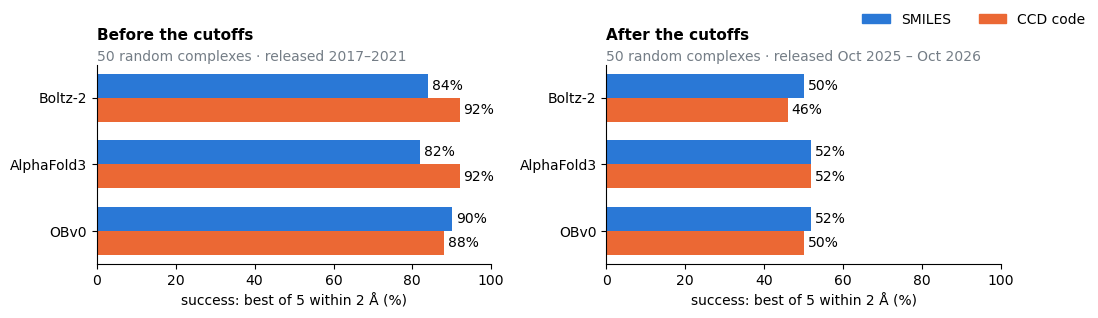

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
C.grouped_bars(axes[0], res["before"][1], "Before the cutoffs", "50 random complexes · released 2017–2021")
C.grouped_bars(axes[1], res["after"][1], "After the cutoffs", "50 random complexes · released Oct 2025 – Oct 2026")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=C.SMILES), plt.Rectangle((0, 0), 1, 1, color=C.CCD)], ["SMILES", "CCD code"],
           loc="upper right", ncol=2, frameon=False, fontsize=10)
fig.tight_layout(rect=(0, 0, 0.94, 0.97))
fig.savefig(C.FIGS / "fig5_random_complexes.png", dpi=160, bbox_inches="tight")
plt.show()